<a href="https://colab.research.google.com/github/ashleysoni5/EDA/blob/main/House_Price_EDA_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Colab — House Price EDA

1. Open this notebook in Google Colab.
2. Run the first setup cell.
3. When prompted, upload your Kaggle `train.csv`.
4. Select **Runtime → Run all**.

The notebook performs the complete 10-step EDA and generates `eda_dashboard.png`.


# Exploratory Data Analysis of House Prices
### Ames Housing Dataset | Essentials of AI

**Project type:** Exploratory Data Analysis (EDA) — no machine-learning model is trained.

**Dataset:** Kaggle *House Prices: Advanced Regression Techniques*, `train.csv`  
**Rows and columns:** 1,460 observations and 81 columns (verified from the supplied file).

## Objective
Explore the distribution of house sale prices and investigate how numerical, categorical and ordinal property features relate to `SalePrice`. The project follows the 10-step methodology in the course project brief.

## Guiding questions
1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does `OverallQual` change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or unusual sales?
6. Which columns have missing values, and which missing values indicate an absent feature?

## Dataset files
The accompanying `train.csv` contains the labelled training data. `data_description.txt` explains the variables and category codes. `test.csv` and `sample_submission.csv` are not needed for this EDA-only project.

## 1. Setup and first look
Import the required libraries, load the supplied CSV, inspect its shape and first rows, and summarize missing values.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 12

# In Google Colab, upload train.csv when prompted.
import os
if not os.path.exists("train.csv"):
    from google.colab import files
    print("Select the Kaggle train.csv file.")
    uploaded = files.upload()

if not os.path.exists("train.csv"):
    raise FileNotFoundError("Please upload the Kaggle file named train.csv, then rerun this cell.")

df = pd.read_csv("train.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn information:")
df.info()

missing_count = df.isnull().sum().sort_values(ascending=False)
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": (missing_count / len(df) * 100).round(2)
})
missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]
print("\\nColumns with missing values:", len(missing_summary))
display(missing_summary)

Select the Kaggle train.csv file.


Saving train.csv to train (1).csv
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null  

,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


**Initial observation:** The supplied training file contains 1,460 rows and 81 columns. The missing-value table identifies columns that need interpretation before cleaning. In this dataset, some `NA` values mean that a feature (for example, a pool or alley) is absent rather than that its value is unknown.

## 2. Classify variables
Identify numerical and categorical columns. `OverallQual` is stored as a number but is ordinal because its values represent an ordered quality scale.

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

ordinal_orders = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}
df_typed = df.copy()
for col, order in ordinal_orders.items():
    if col in df_typed.columns:
        df_typed[col] = pd.Categorical(df_typed[col], categories=order, ordered=True)

variable_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": [df[c].nunique(dropna=True) for c in df.columns],
    "Example_Values": [
        ", ".join(map(str, df[c].dropna().unique()[:4])) for c in df.columns
    ]
})
display(variable_summary.head(30))
print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("Ordinal examples: OverallQual (1–10), ExterQual and KitchenQual (Po < Fa < TA < Gd < Ex).")

,Column,Data_Type,Unique_Values,Example_Values
0,Id,int64,1460,"1, 2, 3, 4"
1,MSSubClass,int64,15,"60, 20, 70, 50"
2,MSZoning,object,5,"RL, RM, C (all), FV"
3,LotFrontage,float64,110,"65.0, 80.0, 68.0, 60.0"
4,LotArea,int64,1073,"8450, 9600, 11250, 9550"
5,Street,object,2,"Pave, Grvl"
6,Alley,object,2,"Grvl, Pave"
7,LotShape,object,4,"Reg, IR1, IR2, IR3"
8,LandContour,object,4,"Lvl, Bnk, Low, HLS"
9,Utilities,object,2,"AllPub, NoSeWa"


Numerical columns: 38
Categorical columns: 43
Ordinal examples: OverallQual (1–10), ExterQual and KitchenQual (Po < Fa < TA < Gd < Ex).


**Interpretation:** Continuous numerical variables include `SalePrice`, `GrLivArea`, `LotArea`, `TotalBsmtSF` and `GarageArea`. Discrete numerical variables include `YearBuilt`, `YrSold`, `FullBath` and `BedroomAbvGr`. Nominal categorical examples include `Neighborhood`, `HouseStyle`, `SaleCondition` and `MSZoning`. `OverallQual` is ordinal despite its numeric storage type.

## 3. Descriptive statistics
Use mean, median, mode, standard deviation, variance, range, IQR, skewness and kurtosis to summarize important numerical columns.

In [3]:
display(df.describe().T)

stats_rows = []
for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col].dropna()
    stats_rows.append({
        "Feature": col,
        "Mean": s.mean(),
        "Median": s.median(),
        "Mode": s.mode().iloc[0],
        "Std_Dev": s.std(),
        "Variance": s.var(),
        "Range": s.max() - s.min(),
        "IQR": s.quantile(.75) - s.quantile(.25),
        "Skewness": s.skew(),
        "Kurtosis": s.kurtosis()
    })
descriptive_summary = pd.DataFrame(stats_rows).set_index("Feature").round(2)
display(descriptive_summary)

for col in ["Neighborhood", "HouseStyle"]:
    print(f"\\nMost frequent values for {col}:")
    display(df[col].value_counts().head(10).to_frame("Count"))

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,Mean,Median,Mode,Std_Dev,Variance,Range,IQR,Skewness,Kurtosis
Feature,,,,,,,,,
SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,720100,84025.00,1.88,6.54
GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,5308,647.25,1.37,4.90
LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,213945,4048.00,12.21,203.24


\nMost frequent values for Neighborhood:


,Count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


\nMost frequent values for HouseStyle:


,Count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


**Interpretation:** The mean sale price is higher than the median, indicating a right-skewed distribution: a smaller number of expensive houses pull the average upward. The median is more resistant to extreme sale prices than the mean.

## 4. Distribution analysis
Visualize the target variable with a histogram/KDE, boxplot and log transformation. Compare prices across quality levels and neighborhoods.

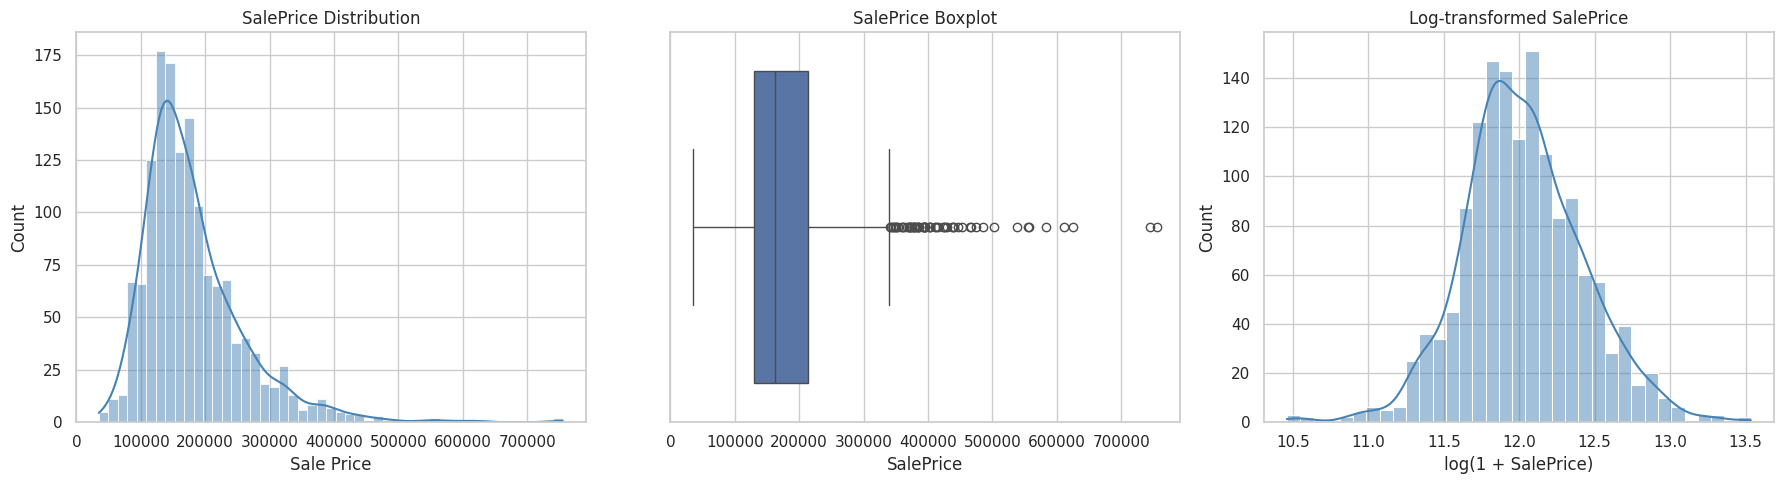

Original SalePrice skewness: 1.883
Log-transformed SalePrice skewness: 0.121


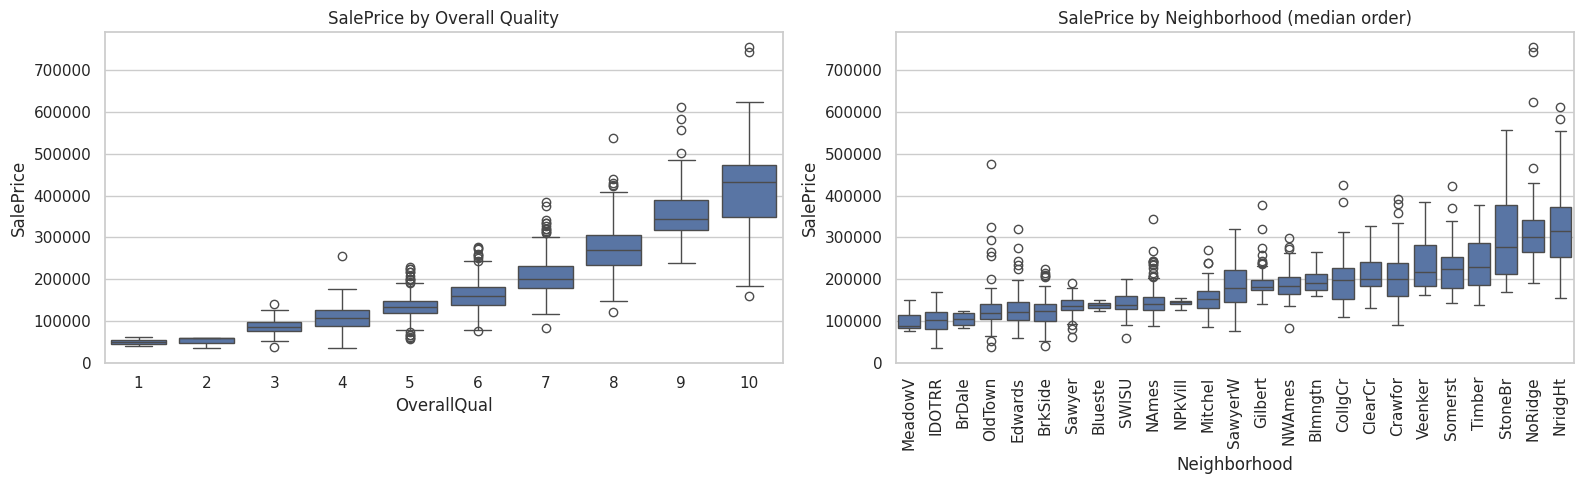

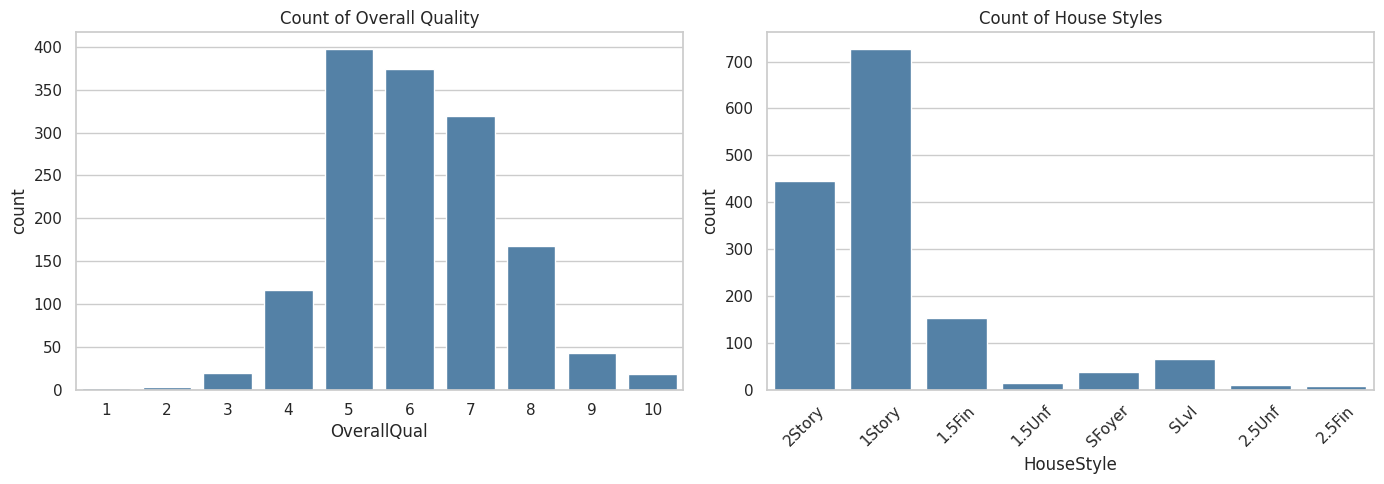

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["SalePrice"], kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price")
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, color="steelblue", ax=axes[2])
axes[2].set_title("Log-transformed SalePrice")
axes[2].set_xlabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()

print("Original SalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("Log-transformed SalePrice skewness:", round(np.log1p(df["SalePrice"]).skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[0])
axes[0].set_title("SalePrice by Overall Quality")
neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neighborhood_order, ax=axes[1])
axes[1].set_title("SalePrice by Neighborhood (median order)")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="OverallQual", color="steelblue", ax=axes[0])
axes[0].set_title("Count of Overall Quality")
sns.countplot(data=df, x="HouseStyle", color="steelblue", ax=axes[1])
axes[1].set_title("Count of House Styles")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:** The raw `SalePrice` distribution has a long right tail. The log transformation compresses high values and reduces the skew. The grouped boxplots help assess whether sale price generally rises with overall quality and how neighborhood price distributions differ.

## 5. Correlation and covariance
Calculate Pearson correlation and covariance for numerical columns, then rank the ten strongest absolute correlations with `SalePrice`.

In [5]:
numeric_data = df.select_dtypes(include=np.number)
cov_matrix = numeric_data.cov()
corr_matrix = numeric_data.corr(method="pearson")

top_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)
top10_features = top_corr.head(10)
correlation_summary = pd.DataFrame({
    "Correlation_with_SalePrice": corr_matrix.loc[top10_features.index, "SalePrice"],
    "Covariance_with_SalePrice": cov_matrix.loc[top10_features.index, "SalePrice"]
}).sort_values("Correlation_with_SalePrice", key=lambda x: x.abs(), ascending=False)
display(correlation_summary.round(3))

print("Correlation is standardized between -1 and +1; covariance depends on the units and scale of the variables.")

,Correlation_with_SalePrice,Covariance_with_SalePrice
OverallQual,0.791,8.690413e+04
GrLivArea,0.709,2.958187e+07
GarageCars,0.640,3.802018e+04
GarageArea,0.623,1.058910e+07
TotalBsmtSF,0.614,2.138442e+07
1stFlrSF,0.606,1.860663e+07
FullBath,0.561,2.453808e+04
TotRmsAbvGrd,0.534,6.891717e+04
YearBuilt,0.523,1.254637e+06
YearRemodAdd,0.507,8.317079e+05


Correlation is standardized between -1 and +1; covariance depends on the units and scale of the variables.


**Interpretation:** Correlation indicates the strength and direction of a linear relationship. A positive correlation means that larger values of one feature tend to occur with larger sale prices; a negative correlation means the opposite. Correlation does not establish causation. For example, `GarageArea` and `GarageCars` may correlate because larger garages generally fit more cars.

## 6. Scatter plots and pair plot
Plot relationships between selected numerical features and `SalePrice`. Inspect very large living areas with unusually low sale prices.

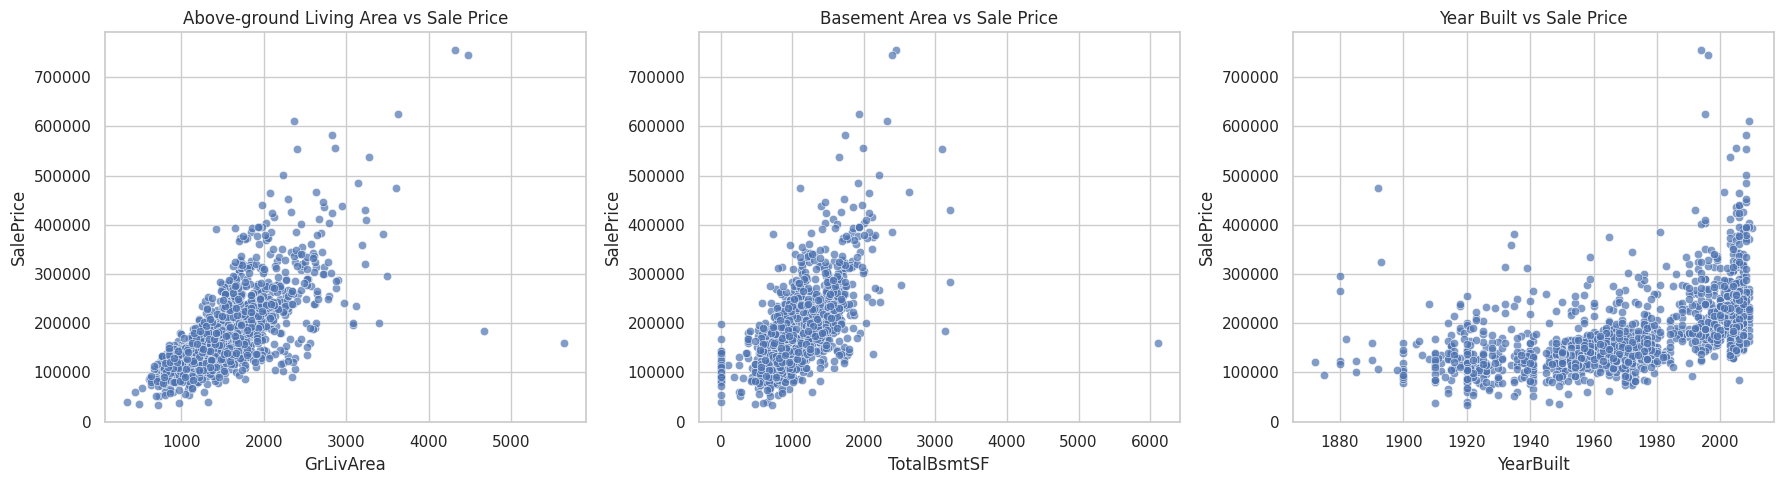

Very large living area with sale price below 25th percentile:


,Id,GrLivArea,SalePrice,OverallQual,Neighborhood


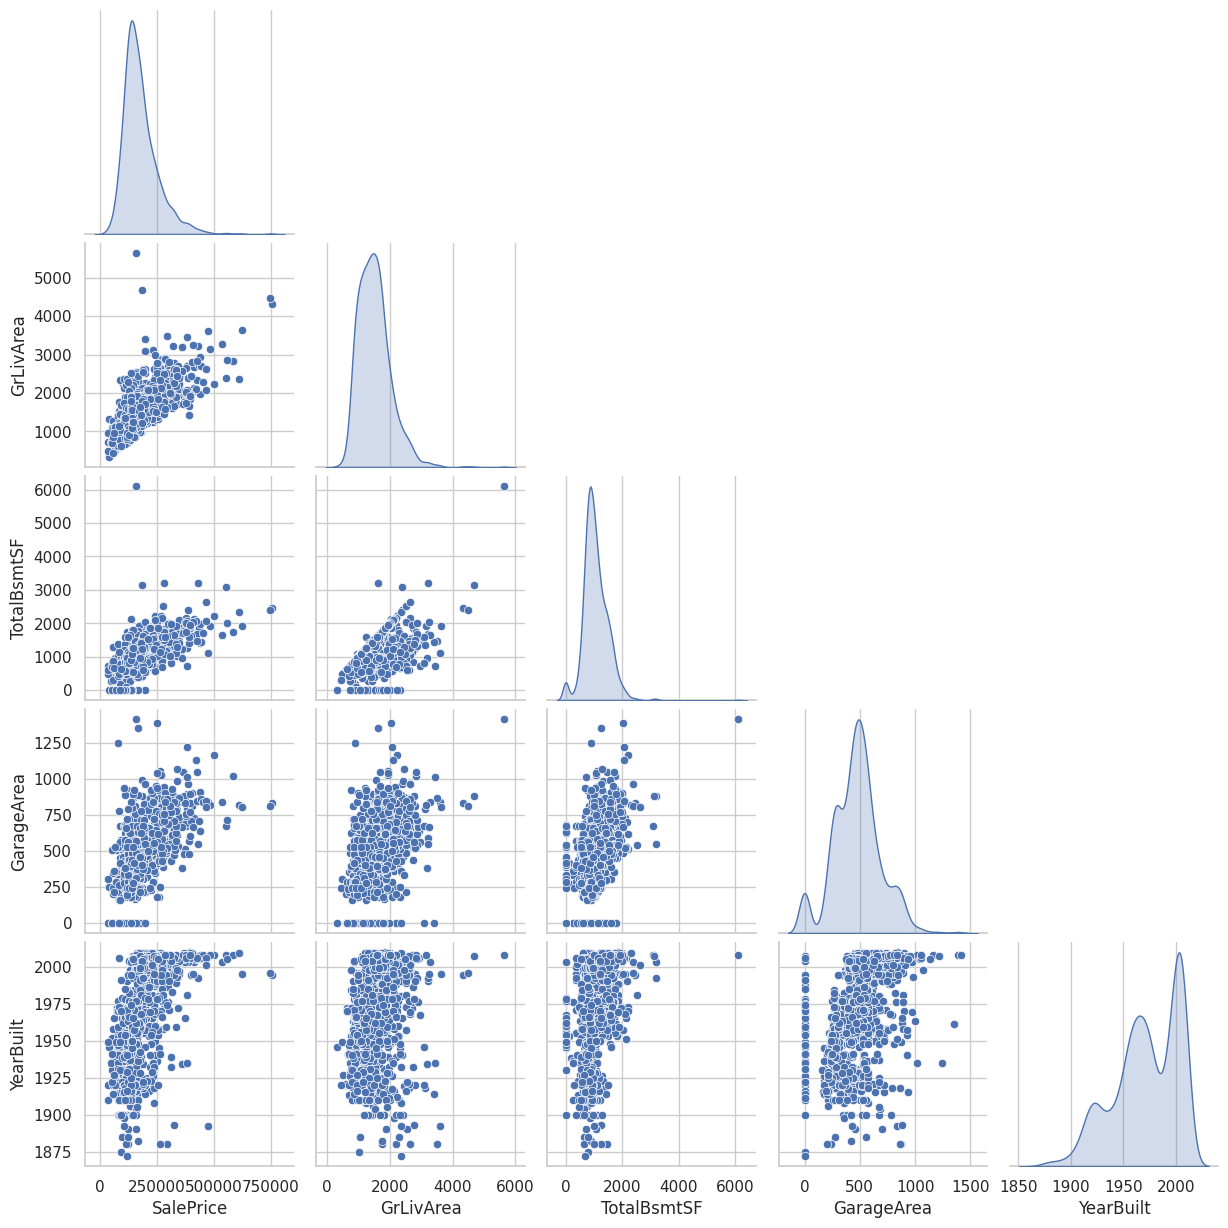

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", ax=axes[0], alpha=.7)
axes[0].set_title("Above-ground Living Area vs Sale Price")
sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", ax=axes[1], alpha=.7)
axes[1].set_title("Basement Area vs Sale Price")
sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", ax=axes[2], alpha=.7)
axes[2].set_title("Year Built vs Sale Price")
plt.tight_layout()
plt.show()

unusual_large_low_price = df[
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < df["SalePrice"].quantile(.25))
]
print("Very large living area with sale price below 25th percentile:")
display(unusual_large_low_price[["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood"]])

pair_columns = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
sns.pairplot(df[pair_columns].dropna(), diag_kind="kde", corner=True)
plt.show()

**Interpretation:** Scatter plots show direction, strength and unusual observations in pairs of numerical variables. The pair plot compares several selected variables at once; its diagonal panels show each variable's distribution.

## 7. Correlation heatmap
Show the correlations among `SalePrice` and the ten numerical features with the strongest absolute correlation to it.

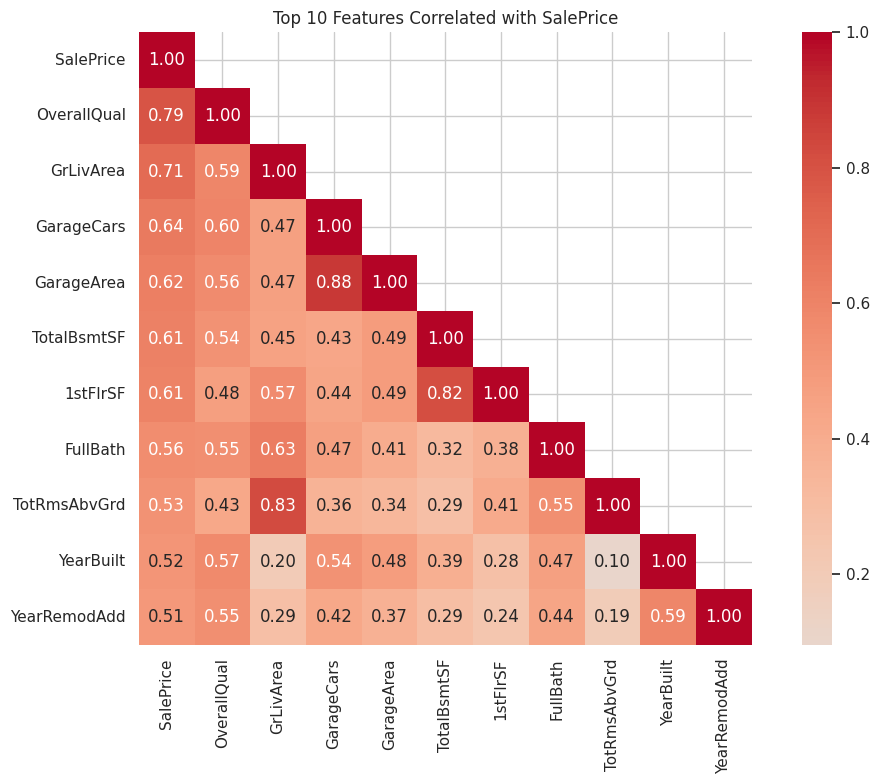

In [7]:
heatmap_columns = ["SalePrice"] + list(top10_features.index)
corr_top = df[heatmap_columns].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, mask=mask, square=True)
plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

**Interpretation:** The heatmap uses color and correlation values to make relationships easier to compare. Values closer to +1 indicate stronger positive linear relationships, values closer to -1 indicate stronger negative linear relationships, and values near 0 indicate weak linear relationships.

## 8. Outlier detection: IQR and Z-score
Use both methods on `GrLivArea` and `SalePrice`. A flagged observation is a candidate for inspection, not automatically an error.

,IQR_Outliers,Z_Score_Outliers,Overlap
Feature,,,
GrLivArea,31,16,16
SalePrice,61,22,22


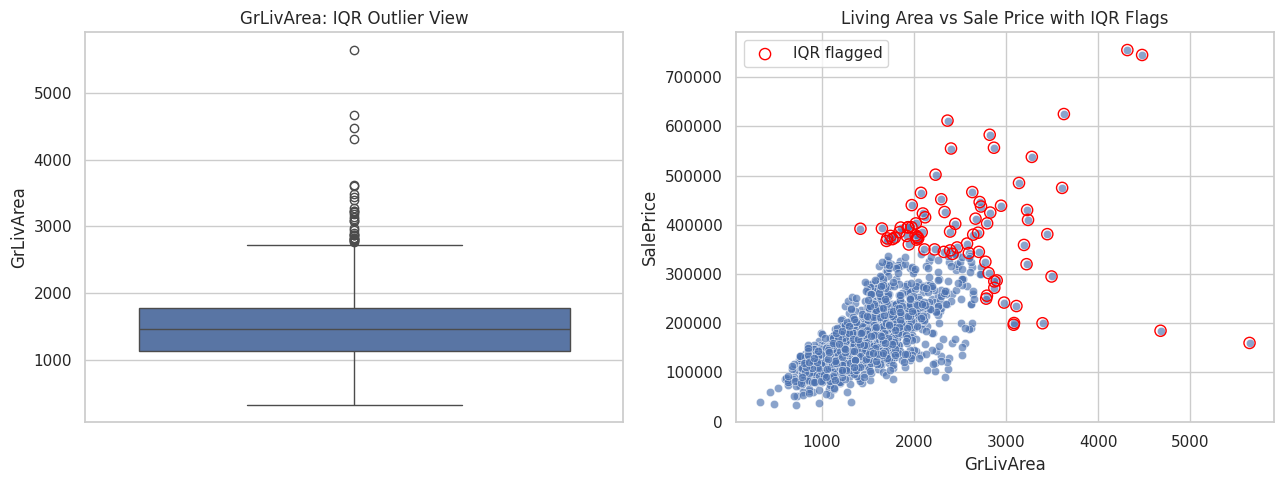

In [8]:
def iqr_outlier_indices(series):
    s = series.dropna()
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].dropna().index

def zscore_outlier_indices(series, threshold=3):
    s = series.dropna()
    z = (s - s.mean()) / s.std()
    return z[abs(z) > threshold].index

outlier_results = []
outlier_index_sets = {}
for col in ["GrLivArea", "SalePrice"]:
    iqr_idx = set(iqr_outlier_indices(df[col]))
    z_idx = set(zscore_outlier_indices(df[col], threshold=3))
    outlier_index_sets[col] = {"IQR": iqr_idx, "Z-score": z_idx}
    outlier_results.append({
        "Feature": col,
        "IQR_Outliers": len(iqr_idx),
        "Z_Score_Outliers": len(z_idx),
        "Overlap": len(iqr_idx & z_idx)
    })
display(pd.DataFrame(outlier_results).set_index("Feature"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea: IQR Outlier View")
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", ax=axes[1], alpha=.65)
flagged = sorted(outlier_index_sets["GrLivArea"]["IQR"] | outlier_index_sets["SalePrice"]["IQR"])
axes[1].scatter(df.loc[flagged, "GrLivArea"], df.loc[flagged, "SalePrice"],
                facecolors="none", edgecolors="red", s=65, label="IQR flagged")
axes[1].set_title("Living Area vs Sale Price with IQR Flags")
axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretation:** IQR uses quartiles and the 1.5 × IQR rule. The Z-score method measures distance from the mean in standard deviations and flags absolute Z-scores above 3. On skewed data, the mean and standard deviation can be influenced by extreme values, so Z-score and IQR may flag different counts. Unusual large houses with low prices should be reviewed before removal.

## 9. Data quality checks and cleaning
Check duplicate rows, normalize text whitespace, treat documented absent-feature values as `None`, and impute selected numeric missing values. Preserve the original data in `df`.

In [9]:
df_clean = df.copy()

duplicate_count = int(df_clean.duplicated().sum())
print("Duplicate rows:", duplicate_count)
if duplicate_count:
    df_clean = df_clean.drop_duplicates()
print("Shape after duplicate check:", df_clean.shape)

# Remove accidental leading/trailing spaces from object columns.
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# In the Ames data dictionary, NA in these columns denotes that the feature is absent.
absence_columns = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "FireplaceQu", "GarageType", "GarageFinish",
    "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature"
]
for col in absence_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("None")

# LotFrontage: neighborhood median first, then overall median as fallback.
if "LotFrontage" in df_clean.columns:
    df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(
        lambda group: group.fillna(group.median())
    )
    df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(df_clean["LotFrontage"].median())

# For remaining numeric columns, use median imputation in this analysis copy.
numeric_missing_cols = df_clean.select_dtypes(include=np.number).columns[
    df_clean.select_dtypes(include=np.number).isnull().any()
].tolist()
for col in numeric_missing_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# For remaining categorical missing values, use an explicit 'Unknown' label.
for col in df_clean.select_dtypes(include=["object", "category"]).columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].astype("object").fillna("Unknown")

print("Remaining missing values:", int(df_clean.isnull().sum().sum()))
print("Columns still containing missing values:")
display(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("YearBuilt later than YrSold:", int((df_clean["YearBuilt"] > df_clean["YrSold"]).sum()))
for col in ["GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea"]:
    print(f"Negative values in {col}:", int((df_clean[col] < 0).sum()))

Duplicate rows: 0
Shape after duplicate check: (1460, 81)
Remaining missing values: 0
Columns still containing missing values:


,0


YearBuilt later than YrSold: 0
Negative values in GrLivArea: 0
Negative values in LotArea: 0
Negative values in TotalBsmtSF: 0
Negative values in GarageArea: 0


**Cleaning decisions:** The data dictionary identifies many `NA` category values as absent features (for example, no basement, no garage, no pool or no fence). Those are labelled `None`, not dropped. `LotFrontage` is filled using the neighborhood median, then the overall median if needed. Remaining numeric missing values are filled with their column median, and remaining categorical gaps are labelled `Unknown`. This creates a separate analysis copy; the original `df` remains unchanged.

## 10. Final dashboard and storytelling
Build the required 2 × 2 dashboard: average sale price by year built, top neighborhoods by average sale price, sale price distribution with mean/median, and living area versus price colored by overall quality.

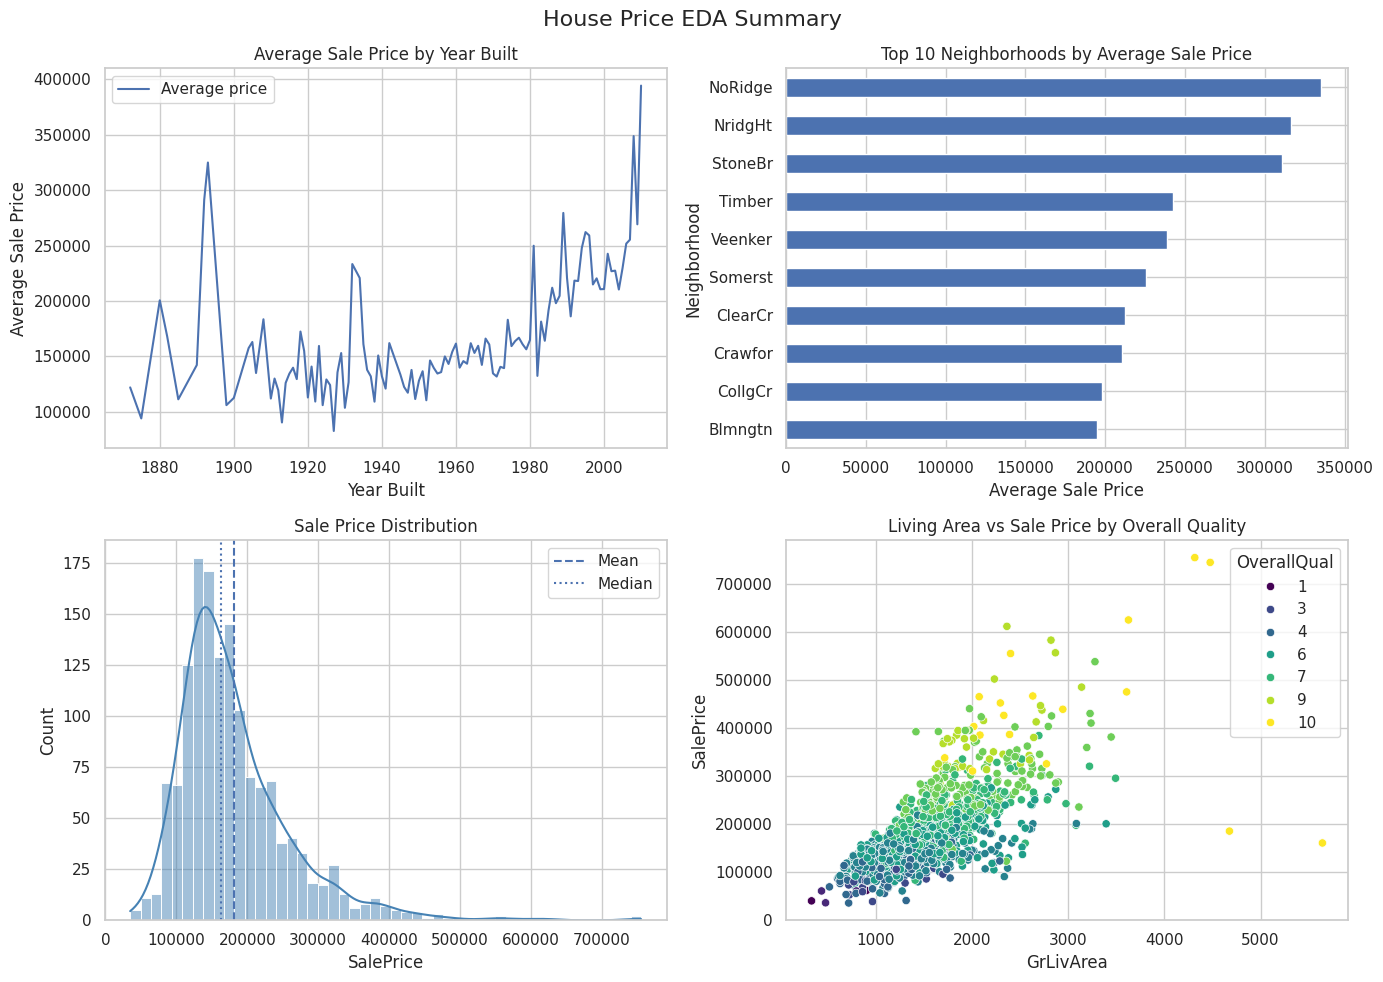

Dashboard saved as eda_dashboard.png


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: mean sale price by original construction year.
year_price = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(year_price.index, year_price.values, label="Average price")
axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()

# Panel 2: ten neighborhoods with highest mean sale price.
neighborhood_mean = df_clean.groupby("Neighborhood")["SalePrice"].mean().nlargest(10).sort_values()
neighborhood_mean.plot(kind="barh", ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Neighborhoods by Average Sale Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: target distribution with mean and median markers.
sns.histplot(df_clean["SalePrice"], kde=True, color="steelblue", ax=axes[1, 0])
axes[1, 0].axvline(df_clean["SalePrice"].mean(), linestyle="--", label="Mean")
axes[1, 0].axvline(df_clean["SalePrice"].median(), linestyle=":", label="Median")
axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].legend()

# Panel 4: living area vs price, colored by ordinal quality score.
sns.scatterplot(data=df_clean, x="GrLivArea", y="SalePrice",
                hue="OverallQual", palette="viridis", ax=axes[1, 1])
axes[1, 1].set_title("Living Area vs Sale Price by Overall Quality")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Dashboard saved as eda_dashboard.png")

## 11. Findings and conclusion
The following values are calculated from the supplied `train.csv`. Use them to explain the findings during the viva.

In [11]:
sale_mean = df["SalePrice"].mean()
sale_median = df["SalePrice"].median()
sale_skew = df["SalePrice"].skew()
log_skew = np.log1p(df["SalePrice"]).skew()
quality_medians = df.groupby("OverallQual")["SalePrice"].median()
neighborhood_medians = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)
strongest = corr_matrix["SalePrice"].drop("SalePrice").sort_values(key=lambda s: s.abs(), ascending=False).head(5)

print(f"Mean SalePrice: ${sale_mean:,.2f}")
print(f"Median SalePrice: ${sale_median:,.2f}")
print(f"SalePrice skewness: {sale_skew:.3f}")
print(f"Log SalePrice skewness: {log_skew:.3f}")
print("\\nTop 5 numerical correlations with SalePrice:")
display(strongest.to_frame("Pearson correlation"))
print("\\nMedian SalePrice by OverallQual:")
display(quality_medians.to_frame("Median SalePrice"))
print("\\nFive neighborhoods with highest median SalePrice:")
display(neighborhood_medians.head(5).to_frame("Median SalePrice"))
print("\\nNumber of rows in cleaned analysis copy:", len(df_clean))

Mean SalePrice: $180,921.20
Median SalePrice: $163,000.00
SalePrice skewness: 1.883
Log SalePrice skewness: 0.121
\nTop 5 numerical correlations with SalePrice:


,Pearson correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581


\nMedian SalePrice by OverallQual:


,Median SalePrice
OverallQual,
1,50150.0
2,60000.0
3,86250.0
4,108000.0
5,133000.0
6,160000.0
7,200141.0
8,269750.0
9,345000.0


\nFive neighborhoods with highest median SalePrice:


,Median SalePrice
Neighborhood,
NridgHt,315000.0
NoRidge,301500.0
StoneBr,278000.0
Timber,228475.0
Somerst,225500.0


\nNumber of rows in cleaned analysis copy: 1460


### Conclusion

Based on the computed dataset results:

- The sale-price distribution is positively skewed; comparing mean and median shows the influence of higher-priced sales.
- The log transformation reduces the influence of the long right tail; compare the two printed skewness values.
- The ranked correlation table identifies which numerical features have the strongest linear association with `SalePrice`.
- The quality-level and neighborhood boxplots/median table show how sale prices vary across property quality and location.
- IQR and Z-score identify candidate outliers; these are not automatically deleted because some may be legitimate unusual sales.
- Missing values were interpreted using the data dictionary so that an absent feature was not mistaken for an unknown value.

**Limitations:** This is an observational EDA study of the Kaggle training dataset. Correlation does not imply causation, and the analysis does not predict prices or establish causal effects.

## References and submission checklist

- Kaggle: [House Prices — Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)
- Dataset data dictionary: accompanying `data_description.txt`
- Course brief: *EDA Project: Exploratory Analysis of House Prices*

### Final checks
- [x] All ten methodology steps are included.
- [x] Uses the supplied 1,460-row `train.csv`.
- [x] Includes statistical summaries, plots, correlation, outlier checks and data cleaning.
- [x] Generates `eda_dashboard.png`.
- [x] No machine-learning model is trained.
- [ ] Student: review the notebook outputs and be ready to explain the results.
- [ ] Student: create a GitHub repository and push the project.
- [ ] Student: attach the repository/project to AlgoArena as required by the college.